# CIFAR-10 replication of NA-RFM Table 2: results

This notebook displays the results of our replication of Table 2 of Wang, Belkin and Wang, "General and Efficient
Steering of Diffusion Models" (ICML 2026, [arXiv 2602.11395](https://arxiv.org/abs/2602.11395)). It does not
generate images: it loads the numbers and figures that `replicate.py` saved in `results/` after running on a DSMLP
GPU pod (GTX 1080 Ti). It runs in a few seconds on any machine. How to rerun the experiment is in `README.md`.

Setup: 256 images per class (seeds 0-255), 100 DDIM steps, ten classes. Accuracy is the share of images the paper's
ConvNeXt-Tiny evaluator assigns to the requested class. FID compares each class's images with that class's 6,000
CIFAR-10 images and is averaged over classes.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

R = Path("results")
if not R.exists():                       # opened from the repo root
    R = Path("cifar10_replication/results")
load = lambda name: json.load(open(R / name))

SETTINGS = {                              # file key -> label
    "unguided": "Unguided (not in Table 2)",
    "na_l3": "Noise alignment only (λ = 3)",
    "na_l8": "Noise alignment only (λ = 8)",
    "rfm_only": "RFM only (all steps)",
    "na_rfm": "NA-RFM",
}
# The paper's Table 2 (2,048 images per class, A100)
PAPER = {
    "na_l3": dict(acc=62.0, fid=99.0, t16=5.8),
    "na_l8": dict(acc=80.0, fid=120.0, t16=5.8),
    "rfm_only": dict(acc=94.8, fid=40.3, t16=6.8),
    "na_rfm": dict(acc=96.6, fid=41.4, t16=6.2),
}
quality = {k: load(f"quality_{k}.json") for k in SETTINGS}
timing = load("timing.json")
print("GPU:", timing["gpu"])

GPU: NVIDIA GeForce GTX 1080 Ti


## 1. Table 2: ours next to the paper's

The paper's FIDs use 2,048 images per class; ours here use 256, and FID falls as the number of images grows, so
compare our FIDs with each other, not with the paper's. Section 4 repeats two settings at 2,048.

In [2]:
def acc(q):
    c = q["classes"]
    return 100 * sum(x["correct"] for x in c) / sum(x["total"] for x in c)

rows = []
for k, label in SETTINGS.items():
    p = PAPER.get(k, {})
    rows.append({
        "Setting": label,
        "Accuracy, ours (%)": acc(quality[k]),
        "Accuracy, paper (%)": p.get("acc"),
        "FID, ours (256/class)": quality[k]["average_fid"],
        "FID, paper (2,048/class)": p.get("fid"),
        "s / image, batch 64": timing[k]["s_per_image_b64"],
        "s / 16 images, ours (1080 Ti)": timing[k]["s_per_batch16"],
        "s / 16 images, paper (A100)": p.get("t16"),
    })
table = pd.DataFrame(rows).set_index("Setting")
table.style.format(precision=1, na_rep="–").format(precision=3, subset=["s / image, batch 64"])

,"Accuracy, ours (%)","Accuracy, paper (%)","FID, ours (256/class)","FID, paper (2,048/class)","s / image, batch 64","s / 16 images, ours (1080 Ti)","s / 16 images, paper (A100)"
Setting,,,,,,,
Unguided (not in Table 2),10.0,–,157.8,–,0.199,4.1,–
Noise alignment only (λ = 3),62.0,62.0,91.0,99.0,0.200,4.2,5.8
Noise alignment only (λ = 8),79.8,80.0,111.0,120.0,0.200,4.2,5.8
RFM only (all steps),96.3,94.8,94.9,40.3,0.398,8.3,6.8
NA-RFM,95.7,96.6,94.1,41.4,0.340,7.1,6.2


Accuracy matches the paper within about 1 point for every setting. Both RFM settings reach about 96%, against
62-80% for noise alignment alone. NA-RFM takes about 1.7 times as long as unguided sampling on our GPU.

## 2. Per class: RFM classifier AUC, then accuracy / FID for each setting

In [3]:
auc = load("rfm_auc.json")
classes = [c["name"] for c in quality["na_rfm"]["classes"]]
per = pd.DataFrame(index=classes)
per["RFM AUC"] = [round(auc[c], 3) for c in classes]
for k, label in SETTINGS.items():
    per[label] = [f'{x["accuracy"]:.0f} / {x["fid"]:.0f}' for x in quality[k]["classes"]]
per

,RFM AUC,Unguided (not in Table 2),Noise alignment only (λ = 3),Noise alignment only (λ = 8),RFM only (all steps),NA-RFM
airplane,0.931,11 / 159,77 / 99,96 / 131,97 / 106,99 / 98
automobile,0.967,6 / 172,60 / 73,70 / 84,100 / 63,100 / 66
bird,0.889,7 / 144,41 / 111,61 / 130,93 / 116,96 / 119
cat,0.858,18 / 144,50 / 116,67 / 139,100 / 118,100 / 109
deer,0.885,9 / 139,61 / 98,84 / 129,96 / 97,100 / 100
dog,0.859,12 / 153,60 / 101,77 / 133,98 / 101,96 / 107
frog,0.955,12 / 169,72 / 95,94 / 122,97 / 111,100 / 102
horse,0.899,7 / 158,64 / 80,91 / 90,99 / 84,98 / 83
ship,0.943,11 / 172,77 / 65,88 / 76,93 / 82,84 / 74
truck,0.943,7 / 169,58 / 73,69 / 77,90 / 70,83 / 83


RFM AUC is the held-out (20%) AUC of each class's RFM classifier (class against the other nine), on block-9
features of 1,000 training images per class at σ = 0.21. The lowest accuracies under NA-RFM are ship and truck
(84% and 83%).

## 3. Sample images

One grid per setting; rows are the ten classes.

Unguided (not in Table 2)


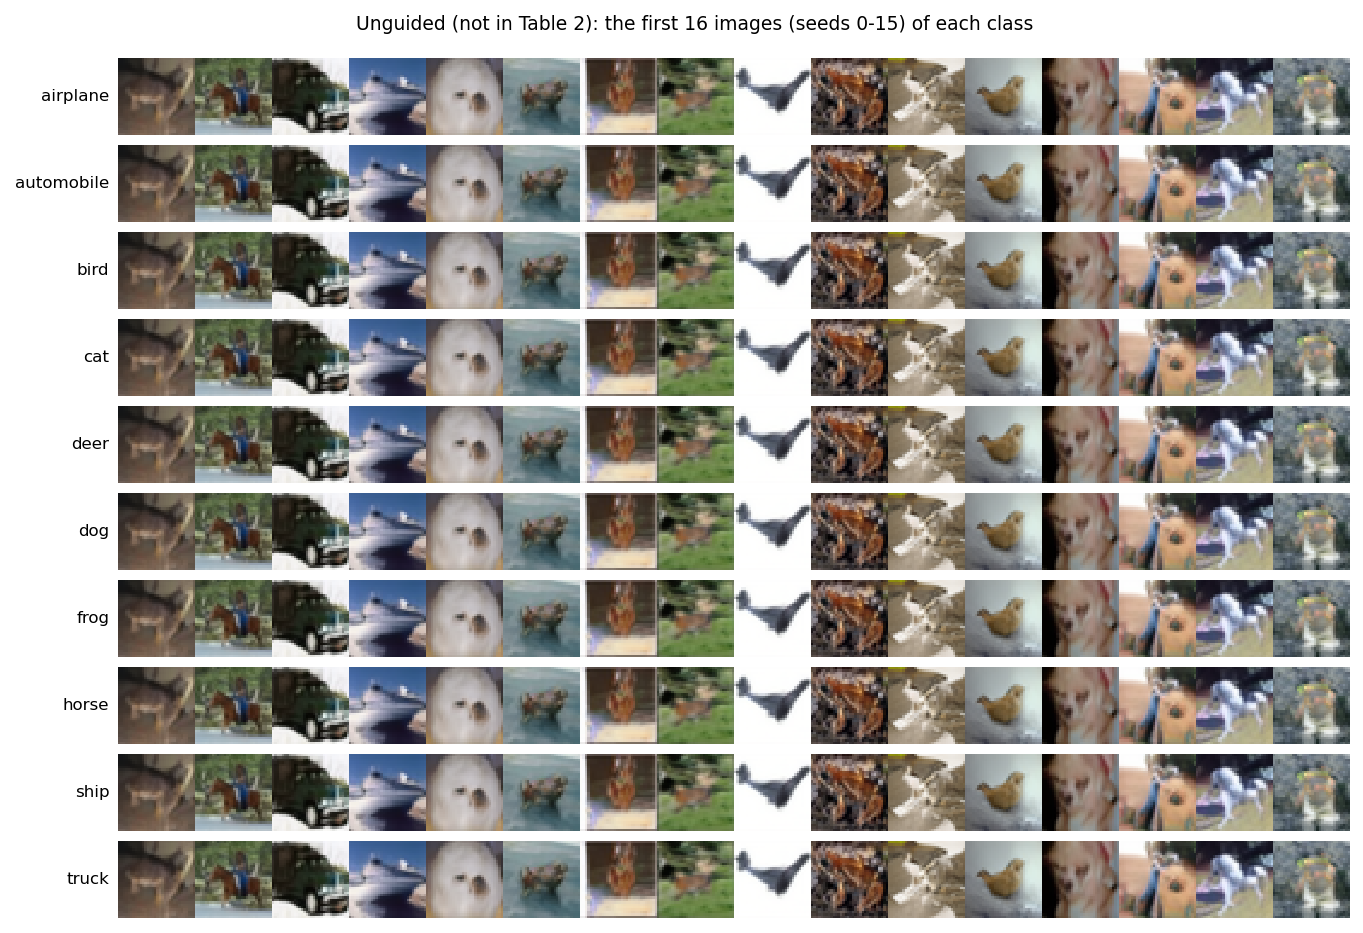

Noise alignment only (λ = 3)


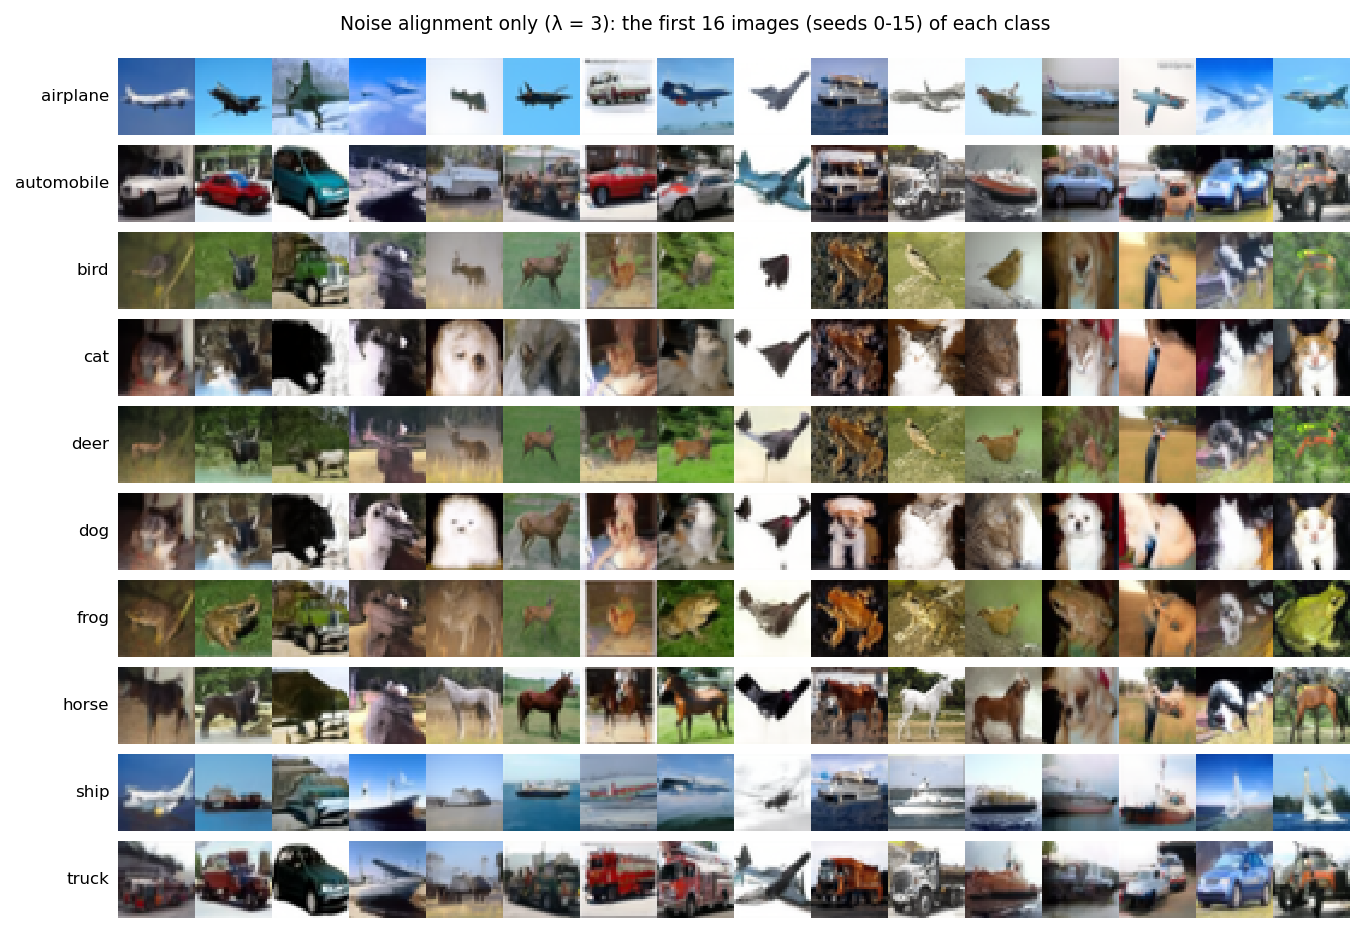

Noise alignment only (λ = 8)


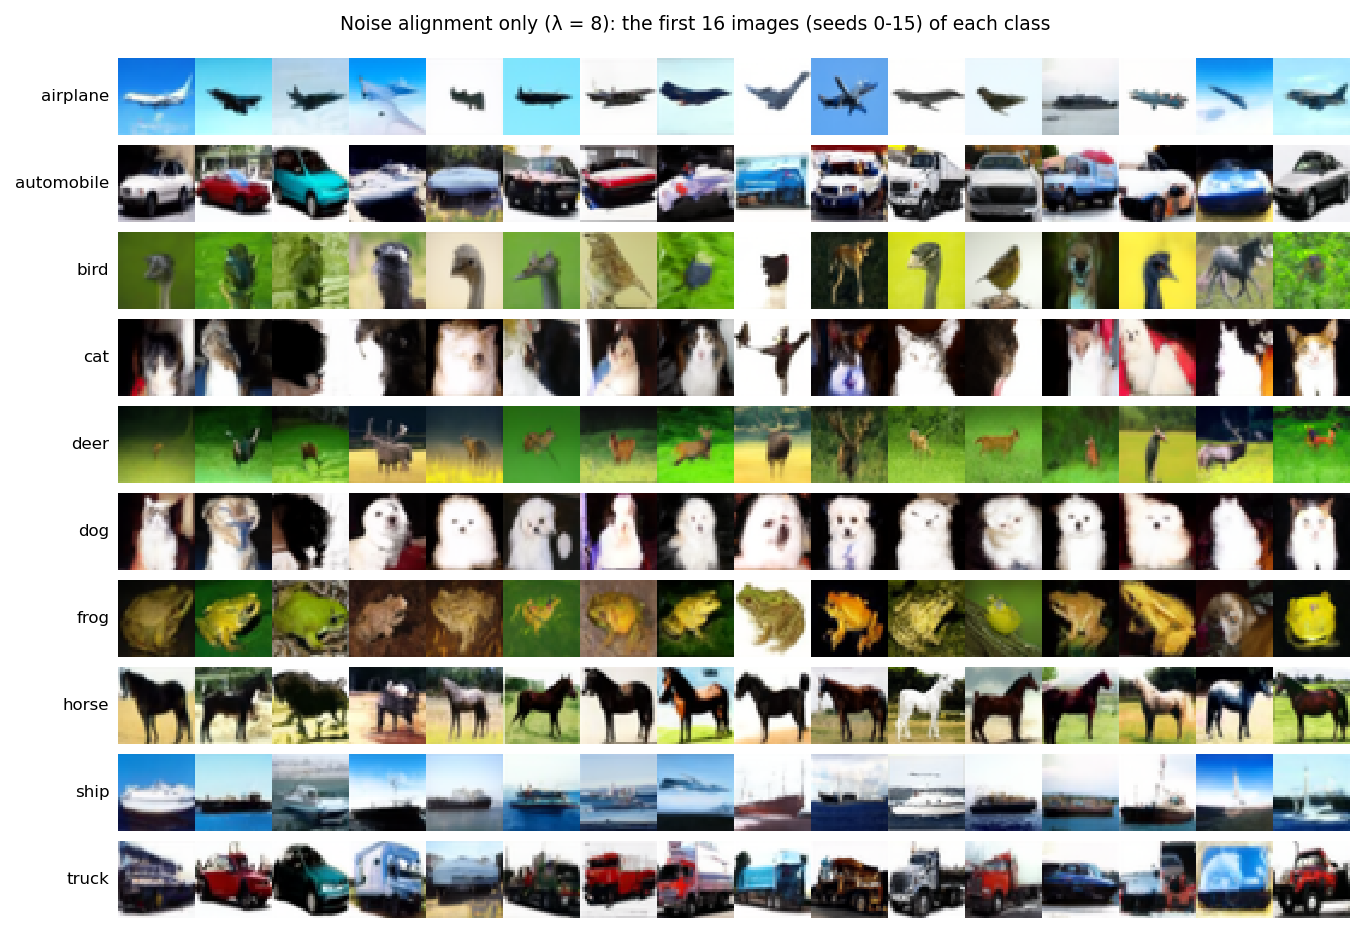

RFM only (all steps)


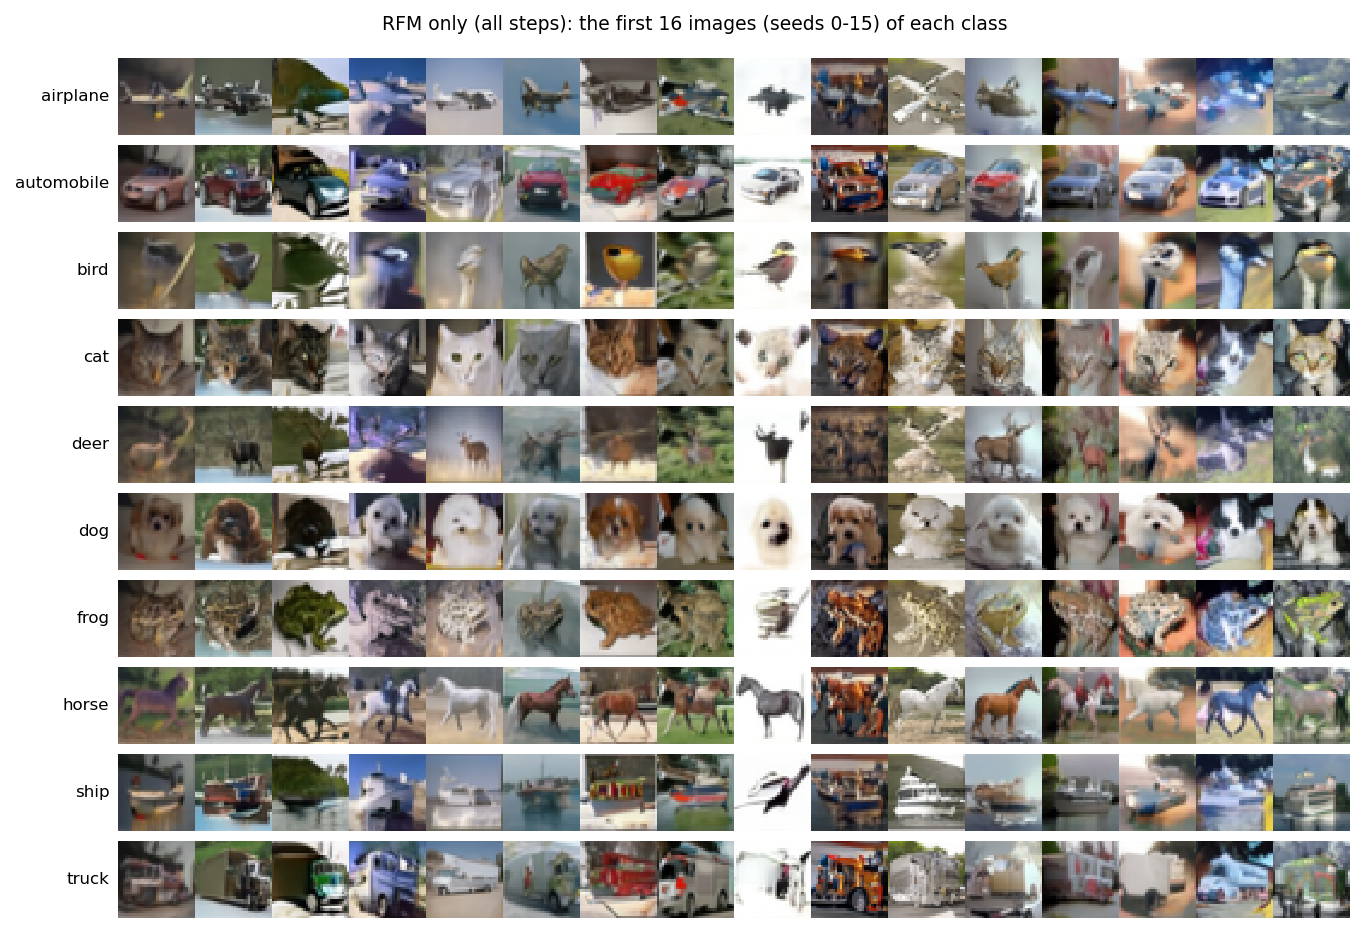

NA-RFM


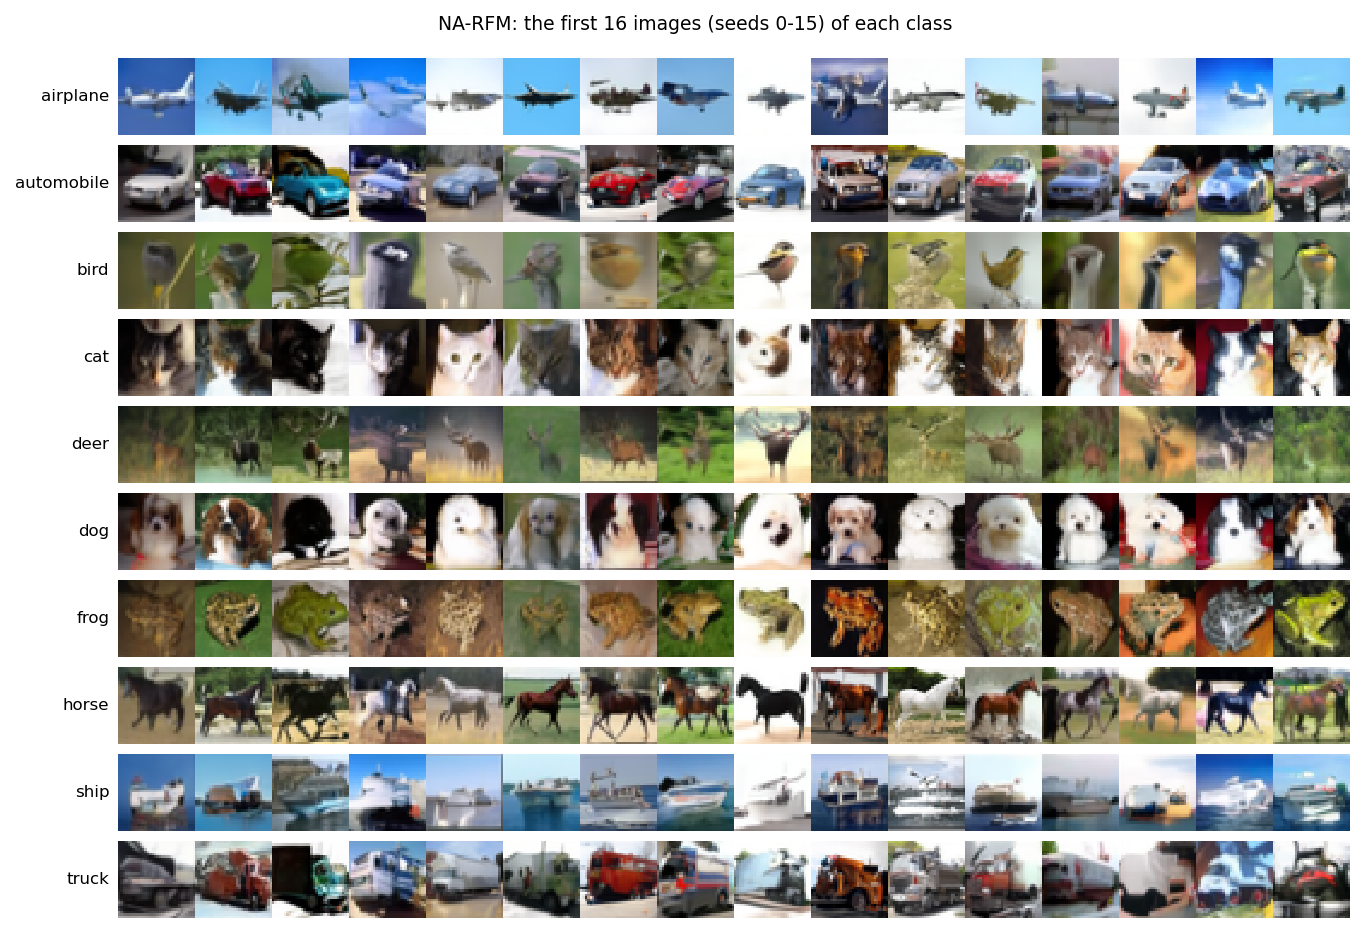

In [4]:
for k, label in SETTINGS.items():
    print(label)
    display(Image(filename=str(R / "figures" / f"grid_{k}.png"), width=640))

Mean steering directions in PCA space:

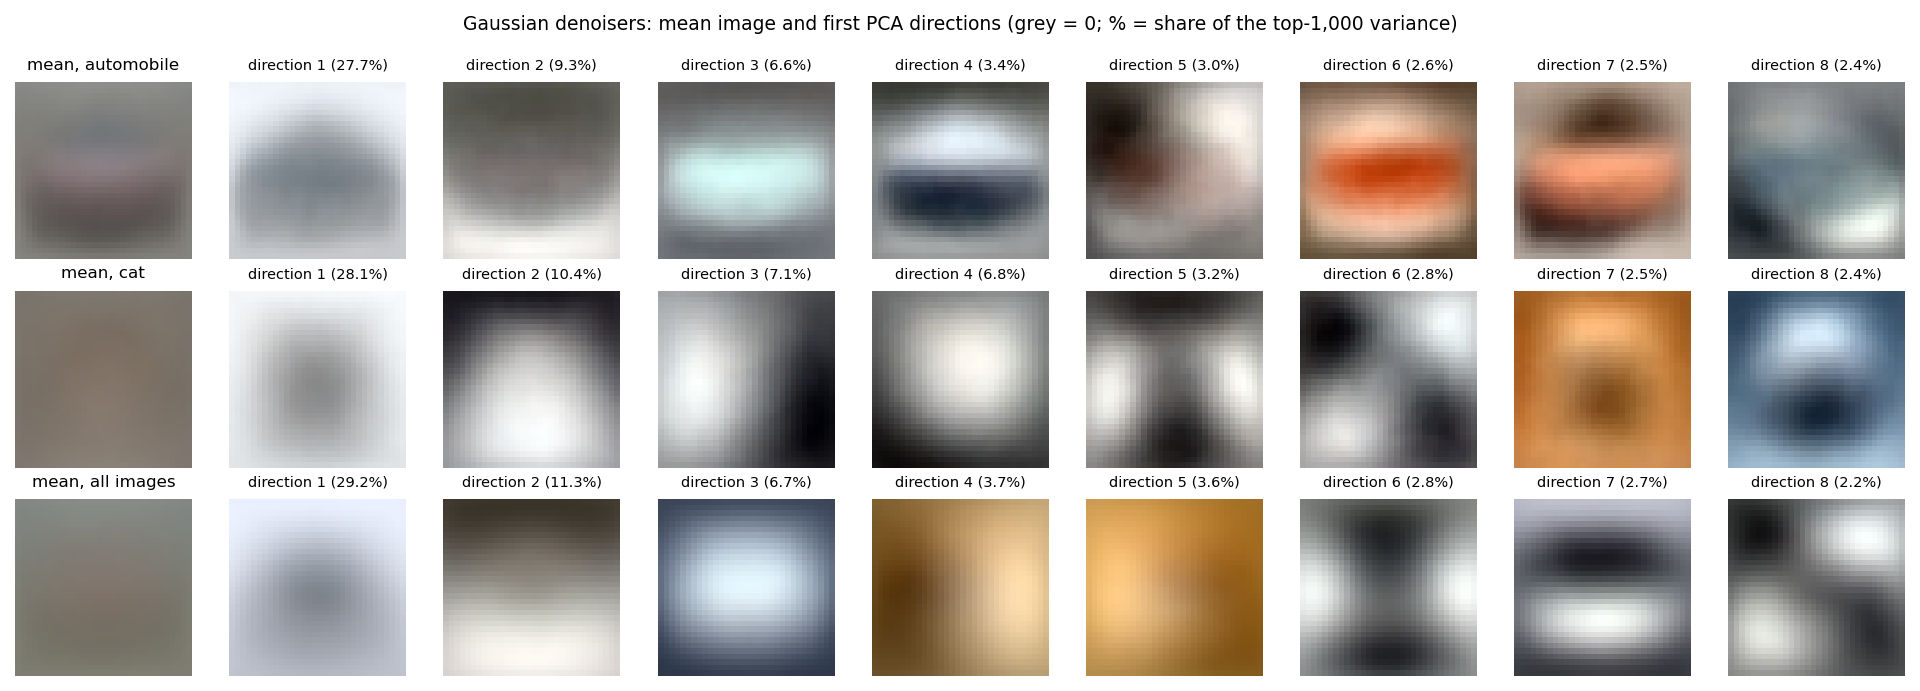

In [5]:
display(Image(filename=str(R / "figures" / "pca_mean_directions.png"), width=640))

## 4. Noise alignment only: accuracy against FID over λ

Raising λ raises accuracy, while FID is lowest near λ = 3 and rises after. The RFM settings sit above the whole curve
(top left): higher accuracy at a similar FID. The figure is the one `replicate.py` saved.

,Accuracy (%),FID
λ,,
1,26.9,121.1
2,46.5,97.9
3,62.0,91.0
5,75.0,96.4
8,79.8,111.0
12,82.0,125.3


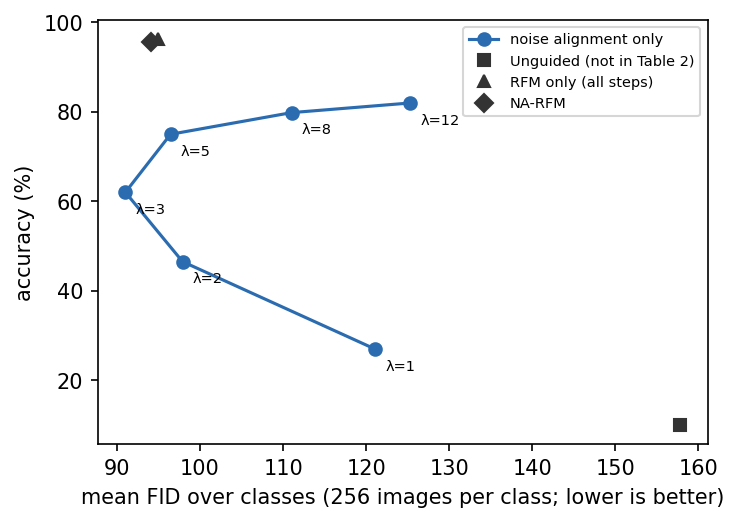

In [6]:
sweep = load("sweep.json")
lams = [k for k in sweep if k.isdigit()]
sw = pd.DataFrame({"λ": [int(l) for l in lams],
                   "Accuracy (%)": [sweep[l]["accuracy"] for l in lams],
                   "FID": [sweep[l]["fid"] for l in lams]}).set_index("λ")
display(sw.round(1))
display(Image(filename=str(R / "figures" / "sweep_acc_fid.png"), width=560))

## 5. FID at up to 2,048 images per class

NA-RFM and noise alignment (λ = 3) were rerun at the paper's 2,048 images per class (seeds 0-2047). Each row uses the
first n images of each class, so the images are the same throughout.

In [7]:
big = load("big.json")
rows = []
for k in ["na_rfm", "na_l3"]:
    for n, v in big[k].items():
        rows.append({"Setting": SETTINGS[k], "Images per class": int(n),
                     "Accuracy (%)": v["accuracy"], "FID, ours": v["fid"],
                     "FID, paper": PAPER[k]["fid"] if n == "2048" else None})
pd.DataFrame(rows).set_index(["Setting", "Images per class"]).style.format(precision=1, na_rep="–")

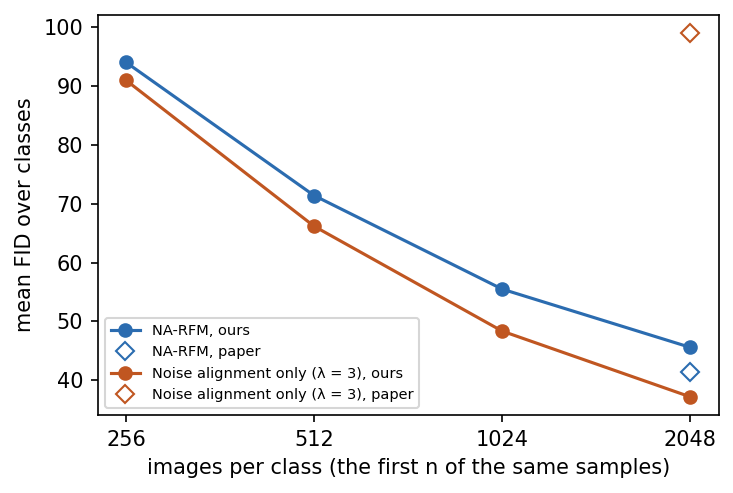

In [8]:
display(Image(filename=str(R / "figures" / "fid_vs_images.png"), width=560))

At 2,048 images NA-RFM's FID (45.6) is close to the paper's 41.4, and accuracy stays near 96%. Noise alignment
at λ = 3 reaches FID 37.1, well below the paper's 99.0, so at equal image counts the two methods are much closer in
FID than the paper's table suggests.

## Summary

- Accuracy replicates: within about 1 point of the paper for all four settings in Table 2.
- FID depends strongly on the number of images; at the paper's 2,048 NA-RFM matches (45.6 vs. 41.4), but our noise
  alignment FID is much lower than the paper's (37.1 vs. 99.0).
- NA-RFM costs about 1.7x unguided sampling time on a GTX 1080 Ti (7.1 s vs. 4.1 s per 16 images).